In [1]:
import shutil
import os

# قائمة بالمجلدات المراد حذفها نهائياً
folders_to_delete = [
    'data_train',
    'data_train_X',
    'data_train_X_2',
    'data_test',
    'data_test_y',
    'data_test_y_2','master'
]

for folder in folders_to_delete:
    if os.path.exists(folder):
        shutil.rmtree(folder)
        print(f"تم حذف المجلد: {folder}")
    else:
        print(f"المجلد غير موجود بالفعل: {folder}")

print("اكتملت عملية التنظيف!")

المجلد غير موجود بالفعل: data_train
المجلد غير موجود بالفعل: data_train_X
المجلد غير موجود بالفعل: data_train_X_2
المجلد غير موجود بالفعل: data_test
المجلد غير موجود بالفعل: data_test_y
المجلد غير موجود بالفعل: data_test_y_2
المجلد غير موجود بالفعل: master
اكتملت عملية التنظيف!


In [2]:
# importing necessary functions
import tensorflow as tf
tf.keras.preprocessing.image.ImageDataGenerator


keras.src.legacy.preprocessing.image.ImageDataGenerator

In [3]:
from tensorflow.keras.utils import array_to_img,img_to_array,load_img

In [4]:
datagen=tf.keras.preprocessing.image.ImageDataGenerator(featurewise_center=False,
    samplewise_center=False,
    featurewise_std_normalization=False,
    samplewise_std_normalization=False,
    zca_whitening=False,
    zca_epsilon=1e-06,
    rotation_range=0,
    width_shift_range=0.0,
    height_shift_range=0.0,
    brightness_range=(0.5,1.5),
    shear_range=0,
    zoom_range=0.2,
    channel_shift_range=0.0,
    fill_mode='nearest',
    cval=0.0,
    horizontal_flip=True,
    vertical_flip=False,
    rescale=None,
    preprocessing_function=None,
    data_format=None,
    validation_split=0.0,
    interpolation_order=1,
    dtype=None)

In [5]:
imag=load_img('/content/drive/MyDrive/download (2).jpg')


In [6]:
X= img_to_array(imag)

In [7]:
X=X.reshape((1,)+ X.shape)

In [8]:
i=0

In [9]:
import os

# إنشاء المجلد إذا لم يكن موجودًا
os.makedirs('master', exist_ok=True)

In [10]:

for batch in datagen.flow(X,batch_size=1,save_to_dir='master',save_prefix='Image',save_format='jpeg'):
  i+=1
  if i>4:
    break

In [11]:
import matplotlib.pyplot as plt


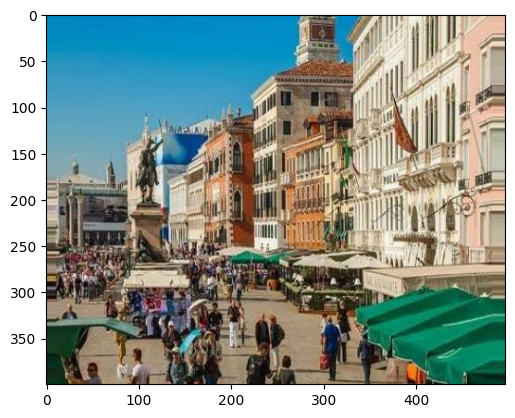

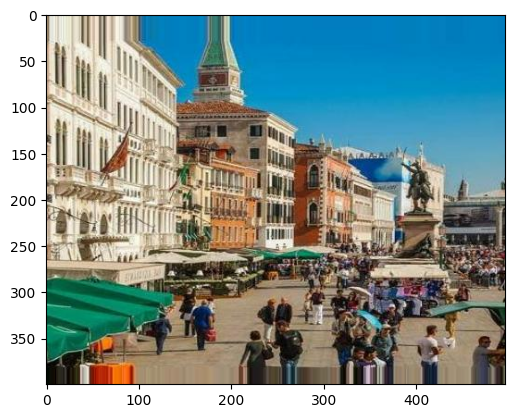

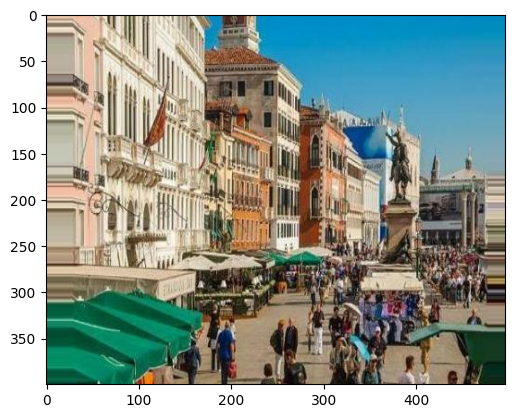

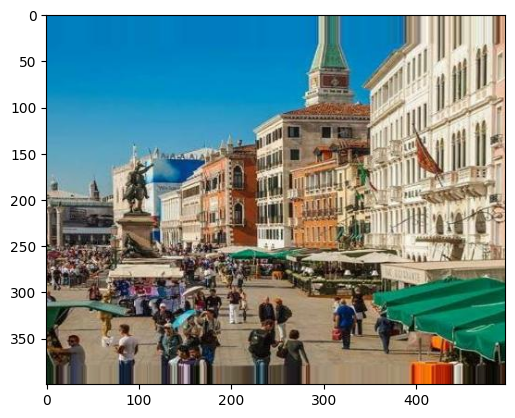

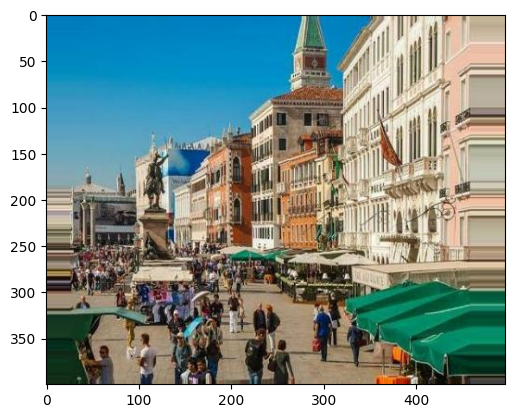

In [12]:

for i in os.listdir('master'):
  plt.imshow(plt.imread(os.path.join('master',i)))
  plt.show()

Data ogmentaion

In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
tf.keras.preprocessing.image.ImageDataGenerator


keras.src.legacy.preprocessing.image.ImageDataGenerator

In [14]:
from sklearn.model_selection import train_test_split
from keras.utils import to_categorical,load_img
import matplotlib.pyplot as plt
import random ,os

Define constant

In [15]:
fast_run=False
IMAGE_WIDTH=128
IMAGE_HEIGHT=128
IMAGE_SIZE=(IMAGE_WIDTH,IMAGE_HEIGHT)
IMAGE_CHANNELS=3

prepare traning Data

In [16]:

os.environ['KAGGLE_USERNAME'] = ""
os.environ['KAGGLE_KEY'] = ""

print("جاري تحميل داتا سيت Cats vs Dogs من كاجل ...")

!kaggle datasets download -d shaunthesheep/microsoft-catsvsdogs-dataset --unzip -p ./cats_dogs_data

print("اكتمل التحميل وفك الضغط بنجاح! البيانات جاهزة الآن في مجلد cats_dogs_data.")

جاري تحميل داتا سيت Cats vs Dogs من كاجل ...
Dataset URL: https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset
License(s): other
100% 788M/788M [00:47<00:00, 17.3MB/s]

اكتمل التحميل وفك الضغط بنجاح! البيانات جاهزة الآن في مجلد cats_dogs_data.


In [17]:
import os
import shutil
import random

# 1. إنشاء مجلدات الترين والتست العامة
os.makedirs('data_train_X_2', exist_ok=True)
os.makedirs('data_test_y_2', exist_ok=True)

# 2. تحديد المسارات الأصلية
cat_dir = '/content/cats_dogs_data/PetImages/Cat'
dog_dir = "/content/cats_dogs_data/PetImages/Dog"

# 3. جلب قوائم الملفات وترتيبها
cats = sorted(os.listdir(cat_dir))
dogs = sorted(os.listdir(dog_dir))

# 4. تقسيم البيانات (900 للتدريب و 150 للاختبار لكل نوع)
cats_train = cats[:900]
dogs_train = dogs[:900]

cats_test = cats[900:1050]
dogs_test = dogs[900:1050]

# 5. دمج وتجهيز القوائم مع إضافة نوع الحيوان لتغيير اسم الملف لاحقاً
# القائمة ستحتوي على توابل (اسم الملف الأصلي، المسار الأصلي، الاسم الجديد المميز)
train_pool = []
for f in cats_train: train_pool.append((f, cat_dir, f"cat.{f}"))
for f in dogs_train: train_pool.append((f, dog_dir, f"dog.{f}"))

test_pool = []
for f in cats_test:
    test_pool.append((f, cat_dir, f"0_{f}"))  # تصنيف 0 للقطط
for i in dogs_test:
    test_pool.append((i, dog_dir, f"1_{i}"))  # تصنيف 1 للكلاب (تم تعديل المتغير إلى i)


# 6. عمل خلط عشوائي (Shuffle) للقوائم المدمجة
random.seed(42) # لتثبيت العشوائية والحصول على نفس النتيجة عند إعادة التشغيل
random.shuffle(train_pool)
random.shuffle(test_pool)

# 7. دالة لنسخ الملفات بالأسماء المصنفة رقمياً والمختلطة
def copy_mixed_files(pool_list, destination_folder):
    for original_name, src_dir, new_name in pool_list:
        source_path = os.path.join(src_dir, original_name)
        destination_path = os.path.join(destination_folder, new_name)

        if os.path.isfile(source_path):
            shutil.copy(source_path, destination_path)

# 8. تنفيذ عملية النسخ الفعلي
print("جاري نسخ ملفات التدريب المختلطة وتصنيفها بـ (0 و 1)...")
copy_mixed_files(train_pool, 'data_train_X_2')

print("جاري نسخ ملفات الاختبار المختلطة وتصنيفها )...")
copy_mixed_files(test_pool, 'data_test_y_2')

print(f"تمت العملية بنجاح! ملفات الترين جاهزة في 'data_train_X_2' وملفات التست في 'data_test_y_2'")

جاري نسخ ملفات التدريب المختلطة وتصنيفها بـ (0 و 1)...
جاري نسخ ملفات الاختبار المختلطة وتصنيفها )...
تمت العملية بنجاح! ملفات الترين جاهزة في 'data_train_X_2' وملفات التست في 'data_test_y_2'


In [18]:
len(os.listdir('/content/data_train_X_2')),len(os.listdir('/content/data_test_y_2'))

(1800, 300)

In [19]:
filenams=os.listdir("/content/data_train_X_2")
categories=[]

In [20]:

for filename in filenams:
  category=filename.split(".")[0]
  if category=="cat":
    categories.append(1)
  else:
    categories.append(0)


In [21]:
df=pd.DataFrame({'filename':filenams,'category':categories})

In [22]:
df.head()

,filename,category
0,cat.10418.jpg,1
1,cat.10425.jpg,1
2,cat.10514.jpg,1
3,dog.10344.jpg,0
4,cat.10550.jpg,1


In [23]:
df.tail()

,filename,category
1795,dog.10126.jpg,0
1796,dog.10636.jpg,0
1797,cat.10761.jpg,1
1798,dog.10602.jpg,0
1799,cat.10381.jpg,1


In [24]:
df[df['category']==0]

,filename,category
3,dog.10344.jpg,0
6,dog.10330.jpg,0
8,dog.10692.jpg,0
11,dog.10700.jpg,0
14,dog.10228.jpg,0
...,...,...
1792,dog.10441.jpg,0
1793,dog.10460.jpg,0
1795,dog.10126.jpg,0
1796,dog.10636.jpg,0


In [25]:
df[df['category']==1]

,filename,category
0,cat.10418.jpg,1
1,cat.10425.jpg,1
2,cat.10514.jpg,1
4,cat.10550.jpg,1
5,cat.10069.jpg,1
...,...,...
1790,cat.10297.jpg,1
1791,cat.10520.jpg,1
1794,cat.1048.jpg,1
1797,cat.10761.jpg,1


In [26]:
df['category'].unique()

array([1, 0])

In [27]:
len([i for i in df['filename'].to_list()if 'cat'in i]),len([i for i in df['filename'].to_list()if 'dog'in i])

(900, 900)

see total in count

<Axes: xlabel='category'>

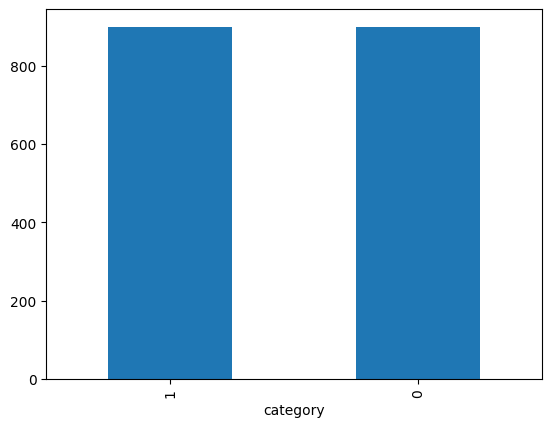

In [28]:
df ['category'].value_counts().plot.bar()

See Sample image

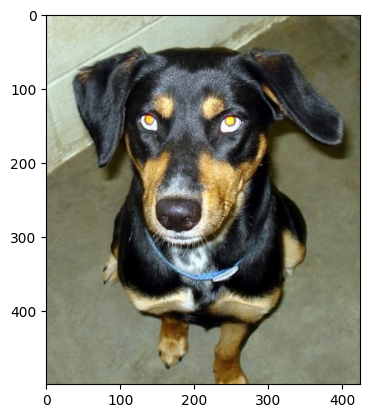

In [29]:
sample=random.choice(filenams)
image=load_img("/content/data_train_X_2/"+ sample)
plt.imshow(image)

Build model

In [30]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dropout, Activation, BatchNormalization, Flatten, Dense

In [31]:
model=Sequential()
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(IMAGE_WIDTH,IMAGE_HEIGHT,IMAGE_CHANNELS)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
# model.add(Dropout(0.25))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.25))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
# model.add(Dropout(0.25))
model.add(Flatten())
# تغيير 'tanh' إلى 'relu' لجعل التعلم أسرع وأكثر مرونة
model.add(Dense(512, activation='relu'))
model.add(BatchNormalization()) # إضافة استقرار للأوزان هنا أيضاً
model.add(Dropout(0.5))        # رفع النسبة إلى 0.5 قبل التصنيف النهائي لحجب التعقيد الزائد

# تم حذف طبقة الـ Dense(64, activation='sigmoid') تماماً لأنها كانت تخنق البيانات وتفقدها دقتها

# طبقة المخرجات النهائية (تصنيف ثنائي إلى فئتين) جاهزة لاستقبال البيانات النقية من الـ 512 مباشرة
model.add(Dense(2, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,942,786 (49.37 MB)

 Trainable params: 12,941,314 (49.37 MB)

 Non-trainable params: 1,472 (5.75 KB)

Callbacks

In [33]:
from keras.callbacks import EarlyStopping,ReduceLROnPlateau

In [34]:
# 1. ضبط الـ EarlyStopping لمراقبة الدقة الفعالة بالاسم الصحيح
earlystop = EarlyStopping(
    monitor='val_accuracy',
    patience=10
)
# 2. تصحيح المسمى والخطأ الإملائي في ReduceLROnPlateau
learning_rate_reduction = ReduceLROnPlateau(
    monitor='val_accuracy',  # التصحيح: استخدام الاسم الكامل المتوافق مع إصدار Keras الحديث
    patience=2,             # التصحيح: تعديل الخطأ الإملائي من patince إلى patience
    verbose=1,
    factor=0.5,
    min_lr=0.00001,
    mode='max'
)

In [35]:
callbacks=[earlystop,learning_rate_reduction]

In [36]:
df['category']=df['category'].replace({1:'cat',0:"dog"})

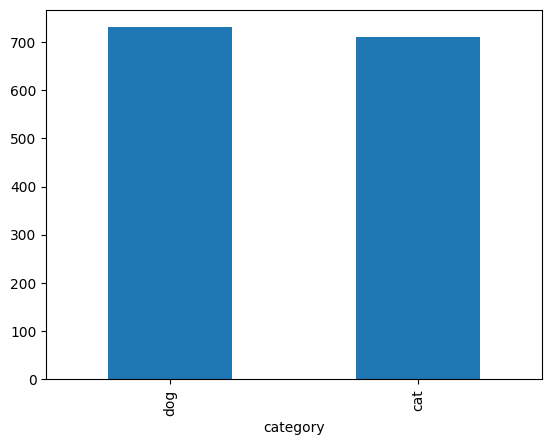

In [37]:
train_df,validate_df=train_test_split(df,test_size=0.20,random_state=42)
train_df=train_df.reset_index(drop=True)
validate_df=validate_df.reset_index(drop=True)
train_df['category'].value_counts().plot.bar()
total_train=train_df.shape[0]
total_validate=validate_df.shape[0]
batch_size=10

Trainnig Generator

In [38]:
print(os.path.exists(os.path.join('/content/data_train_X_2/', train_df['filename'].iloc[0])))

True


In [39]:
traindatagen=tf.keras.preprocessing.image.ImageDataGenerator(rotation_range=15,rescale=1/255,shear_range=0.1,zoom_range=0.2,horizontal_flip=True,
                                                             width_shift_range=0.1,height_shift_range=0.1)
train_genrator=traindatagen.flow_from_dataframe(train_df,'/content/data_train_X_2/',x_col='filename',
                                                y_col='category',
                                                target_size=IMAGE_SIZE,
                                                class_mode='categorical',
                                                batch_size=batch_size)

Found 1440 validated image filenames belonging to 2 classes.


In [40]:

validate_datagen=tf.keras.preprocessing.image.ImageDataGenerator(rescale=1/255)
validate_genrator=validate_datagen.flow_from_dataframe(validate_df,'/content/data_train_X_2/',x_col='filename',
                                                y_col='category',
                                                target_size=IMAGE_SIZE,
                                                class_mode='categorical',
                                                batch_size=batch_size,shuffle=False)

Found 360 validated image filenames belonging to 2 classes.


In [41]:
example_df=train_df.sample(n=1).reset_index(drop=True)
example_genrator=traindatagen.flow_from_dataframe(example_df,'/content/data_train_X_2/',x_col='filename',
                                                y_col='category',
                                                target_size=IMAGE_SIZE,
                                                class_mode='categorical',
                                                batch_size=batch_size)

Found 1 validated image filenames belonging to 1 classes.


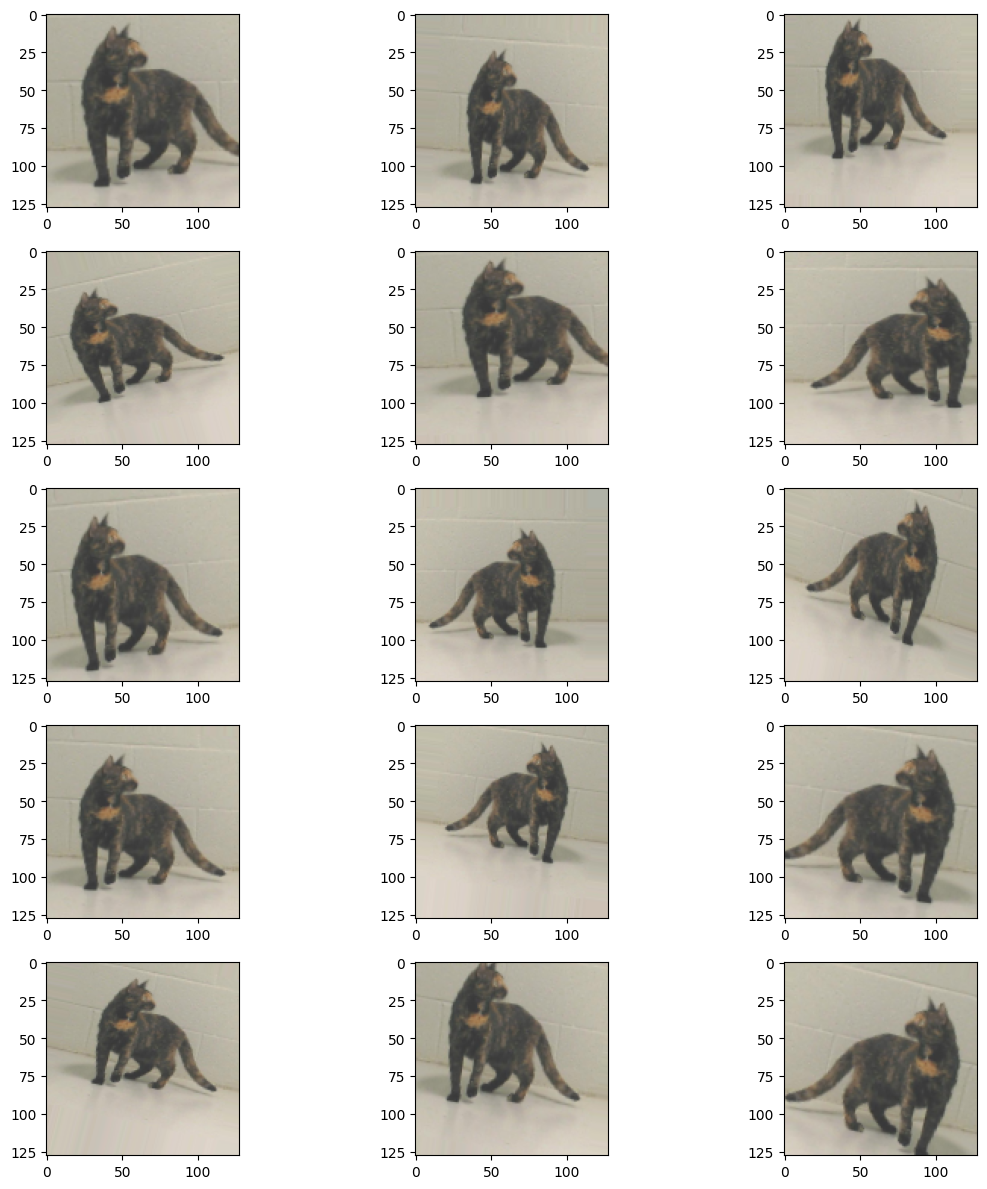

In [42]:
plt.figure(figsize=(12,12))
for i in range(0,15):
  plt.subplot(5,3,i+1)
  for X_batch,Y_batch in example_genrator:
    image=X_batch[0]
    plt.imshow(image)
    break
plt.tight_layout()
plt.show()

In [43]:
import warnings
warnings.filterwarnings('ignore')

In [44]:

epochs=30
history=model.fit(train_genrator,
                            epochs=epochs,
                            validation_data=validate_genrator,
                            validation_steps=total_validate//batch_size,
                            steps_per_epoch=total_train//batch_size,
                            callbacks=callbacks)

Epoch 1/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 30s 93ms/step - accuracy: 0.5785 - loss: 0.9613 - val_accuracy: 0.5278 - val_loss: 2.1849 - learning_rate: 0.0010
Epoch 2/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - accuracy: 0.6201 - loss: 0.7816 - val_accuracy: 0.5444 - val_loss: 0.8858 - learning_rate: 0.0010
Epoch 3/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 25s 107ms/step - accuracy: 0.6250 - loss: 0.7384 - val_accuracy: 0.5944 - val_loss: 0.7492 - learning_rate: 0.0010
Epoch 4/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.6417 - loss: 0.6935 - val_accuracy: 0.6500 - val_loss: 0.6821 - learning_rate: 0.0010
Epoch 5/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - accuracy: 0.6285 - loss: 0.6898 - val_accuracy: 0.4833 - val_loss: 1.2604 - learning_rate: 0.0010
Epoch 6/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.6233 - loss: 0.6990
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - accuracy: 0.6292 - lo

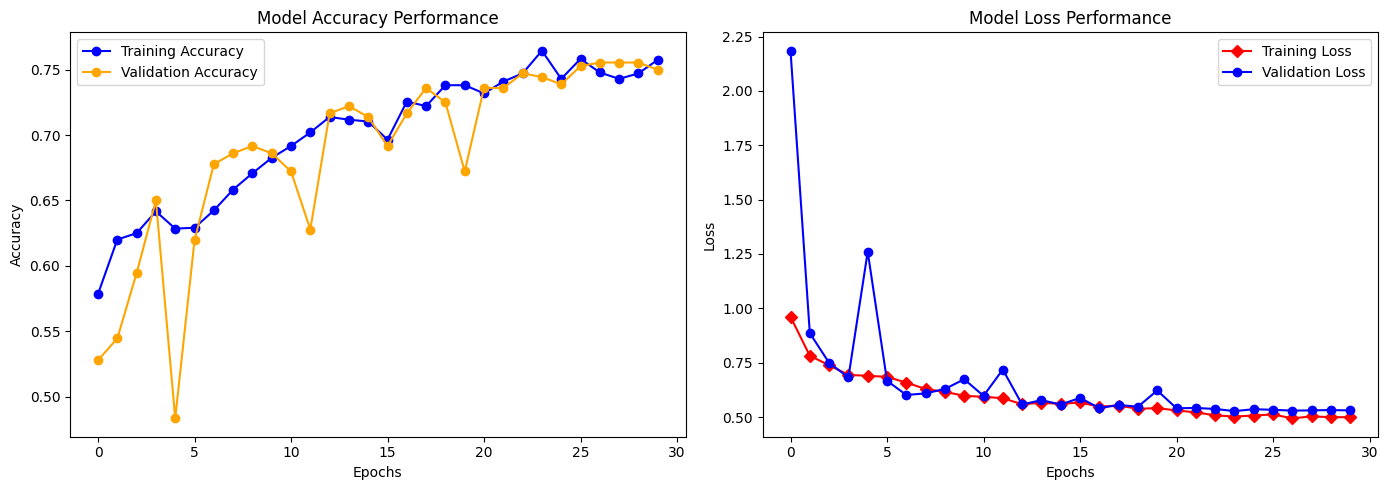

In [45]:
import matplotlib.pyplot as plt

# إنشاء مساحة رسم تحتوي على شكلين بجانب بعضهما
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. رسم منحنى الدقة (Accuracy)
ax1.plot(history.history['accuracy'], label='Training Accuracy', color='blue', marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', marker='o')
ax1.set_title('Model Accuracy Performance')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(False)

# 2. رسم منحنى الخسارة (Loss)
ax2.plot(history.history['loss'], label='Training Loss', color='r', marker='D')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='b', marker='o')
ax2.set_title('Model Loss Performance')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(False)

plt.tight_layout()
plt.show()

In [46]:

# 1. قراءة أسماء الملفات من المجلد الموضح
test_filenames = os.listdir("/content/data_test_y_2")
test_categories = []

for filename in test_filenames:
    # التحقق من الحرف الأول في اسم الملف
    if filename.startswith("0"):
        test_categories.append("cat") # الرقم 0 يعني قطة
    elif filename.startswith("1"):
        test_categories.append("dog") # الرقم 1 يعني كلب
    else:
        test_categories.append("dog") # كخيار احتياطي

# 2. بناء جدول البيانات الصحيح
test_df = pd.DataFrame({
    'filename': test_filenames,
    'category': test_categories
})

print("📊 التوزيع الفعلي المكتشف داخل الجدول الصحيح:")
print(test_df['category'].value_counts())
print("-" * 50)

# 3. تشغيل المولد لبيانات الاختبار (سيظهر لك Belonging to 2 classes بنجاح)
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1/255)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    directory='/content/data_test_y_2/',
    x_col='filename',
    y_col='category',
    target_size=IMAGE_SIZE,
    class_mode='categorical',
    batch_size=batch_size,
    shuffle=False
)

# 4. التقييم النهائي الحقيقي للنموذج
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"\n🎯 الدقة الحقيقية والنهائية لنموذجك على بيانات الاختبار: {test_accuracy * 100:.2f}%")

📊 التوزيع الفعلي المكتشف داخل الجدول الصحيح:
category
dog    150
cat    150
Name: count, dtype: int64
--------------------------------------------------
Found 300 validated image filenames belonging to 2 classes.
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7467 - loss: 0.5489

🎯 الدقة الحقيقية والنهائية لنموذجك على بيانات الاختبار: 74.67%


In [47]:
print(os.listdir("/content/data_test_y_2")[:5])

['1_10835.jpg', '0_10888.jpg', '1_10940.jpg', '1_10857.jpg', '1_10931.jpg']


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


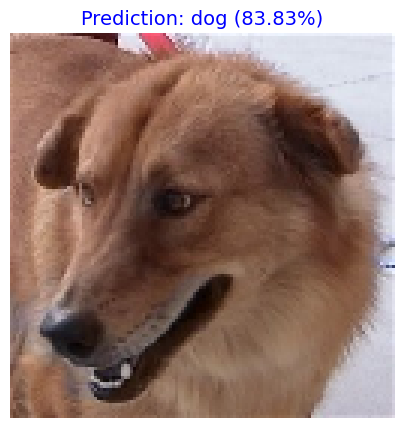

📊 تفاصيل الاحتمالات العميقة -> قطة: 16.17% | كلب: 83.83%


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

def predict_single_image(img_path, model, target_size=IMAGE_SIZE):
    # 1. تحميل الصورة وتغيير أبعادها للمطابقة
    img = image.load_img(img_path, target_size=target_size)

    # 2. تحويل الصورة إلى مصفوفة رقمية وعمل الـ Rescale (1/255)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # 3. تشغيل التوقع عبر النموذج
    predictions = model.predict(img_array)
    predicted_class_idx = np.argmax(predictions)
    confidence = predictions[0][predicted_class_idx] * 100

    # 4. الترتيب الصحيح المعتمد بناءً على نظام المولد لديك
    classes_labels = ['cat', 'dog']
    result_label = classes_labels[predicted_class_idx]

    # 5. عرض الصورة مع النتيجة الدقيقة ونسبة الثقة
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {result_label} ({confidence:.2f}%)",
              fontsize=14,
              color='green' if result_label=='cat' else 'blue')
    plt.axis('off')
    plt.show()

    # قم بتحديث سطر الـ print الأخير داخل دالة التوقع ليكون هكذا:
    print(f"📊 تفاصيل الاحتمالات العميقة -> قطة: {predictions[0][0]*100:.2f}% | كلب: {predictions[0][1]*100:.2f}%")

# جرب تشغيل الدالة الآن على نفس صورة القطة السابقة لتظهر لك النتيجة الصحيحة بنسبة 99.96%!
predict_single_image('/content/cats_dogs_data/PetImages/Dog/10895.jpg', model)

In [49]:
# حفظ النموذج بأحدث صيغة رسمية من Keras
model.save('best_cat_dog_custom_cnn.keras')
print("🎉 مبارك! تم حفظ نموذجك المتكامل بنجاح وهو جاهز للاستخدام مباشرة في أي وقت.")

🎉 مبارك! تم حفظ نموذجك المتكامل بنجاح وهو جاهز للاستخدام مباشرة في أي وقت.
